# The clock: when do problems and stops happen?

**A2.** At what times of day and days of the week do noise complaints, assaults, and collisions peak?

**A6.** How do the timing patterns of calls for service and police stops differ across types of calls and stops?

**A7.** Do traffic stops happen at the same times as collisions, and does this differ between weekdays and weekends?

**Inputs:** `data/processed/calls_2021_2025.csv.gz`, `data/processed/crime_cases_2021_2025.csv.gz`, `data/processed/collisions.csv`, `data/processed/vehicle_stops.csv`

**Outputs:** `figures/03_*.png` and `results/03_*.csv`

In [1]:
# Shared loaders, clock helpers, plot style, and project settings
import matplotlib.pyplot as plt
import pandas as pd

from bpdtools.clock import (
    hour_weekday_table,
    hourly_profile,
    overlap_permutation_test,
    profile_overlap,
    timed_hours,
)
from bpdtools.config import ANALYSIS_END, ANALYSIS_START, ASSAULT_INCIDENT_TYPES
from bpdtools.load import load_calls, load_cases
from bpdtools.paths import repo_path
from bpdtools.plots import (
    plot_hour_weekday_heatmap,
    plot_hourly_profiles,
    set_plot_style,
)
from bpdtools.traffic import load_collisions, load_stops

set_plot_style()

# Figures and result tables go to fixed folders at the repository root
figures = repo_path("figures")
results = repo_path("results")
figures.mkdir(exist_ok=True)
results.mkdir(exist_ok=True)

# Vehicle stops only start in 2024, so A7 uses the two years that stops
# and collisions both cover
STOP_YEARS_START = "2024-01-01"
STOP_YEARS_END = "2025-12-31"

## Load the data

All times are local Berkeley wall clock times.

In [2]:
def in_window(events, start, end):
    """Keep the events whose local time falls in a window of whole days.

    Parameters
    ----------
    events : pandas.DataFrame
        One row per event with a tz-naive `local_time` column.
    start, end : str
        First and last local date of the window, inclusive, as "YYYY-MM-DD".

    Returns
    -------
    pandas.DataFrame
        The rows of `events` from `start` 00:00 up to the end of `end`.
    """
    # The end date is inclusive, so stop before midnight of the next day
    after_end = pd.Timestamp(end) + pd.Timedelta(days=1)
    keep = (events["local_time"] >= pd.Timestamp(start)) & (
        events["local_time"] < after_end
    )
    return events.loc[keep]


# Calls and crime cases are already cut to 2021-2025 by their loaders
calls = load_calls()
cases = load_cases()

# Collisions go back to 2007, so cut them to the same 2021-2025 window
collisions = in_window(load_collisions(), ANALYSIS_START, ANALYSIS_END)

# One row per stop already (counted by LEA_Record_ID)
stops = load_stops()

# Assaults are crime cases of the two assault incident types
assaults = cases.loc[cases["Incident_Type"].isin(ASSAULT_INCIDENT_TYPES)]
noise_calls = calls.loc[calls["call_group"].eq("noise")]

sizes = pd.Series(
    {
        "calls": len(calls),
        "noise calls": len(noise_calls),
        "assault cases": len(assaults),
        "collisions 2021-2025": len(collisions),
        "vehicle stops": len(stops),
    },
    name="rows",
)
sizes

calls                   307628
noise calls              12693
assault cases             3567
collisions 2021-2025      4213
vehicle stops             7431
Name: rows, dtype: int64

## A2 · When do noise, assaults, and collisions peak?

Counts by weekday and hour, 2021-2025.

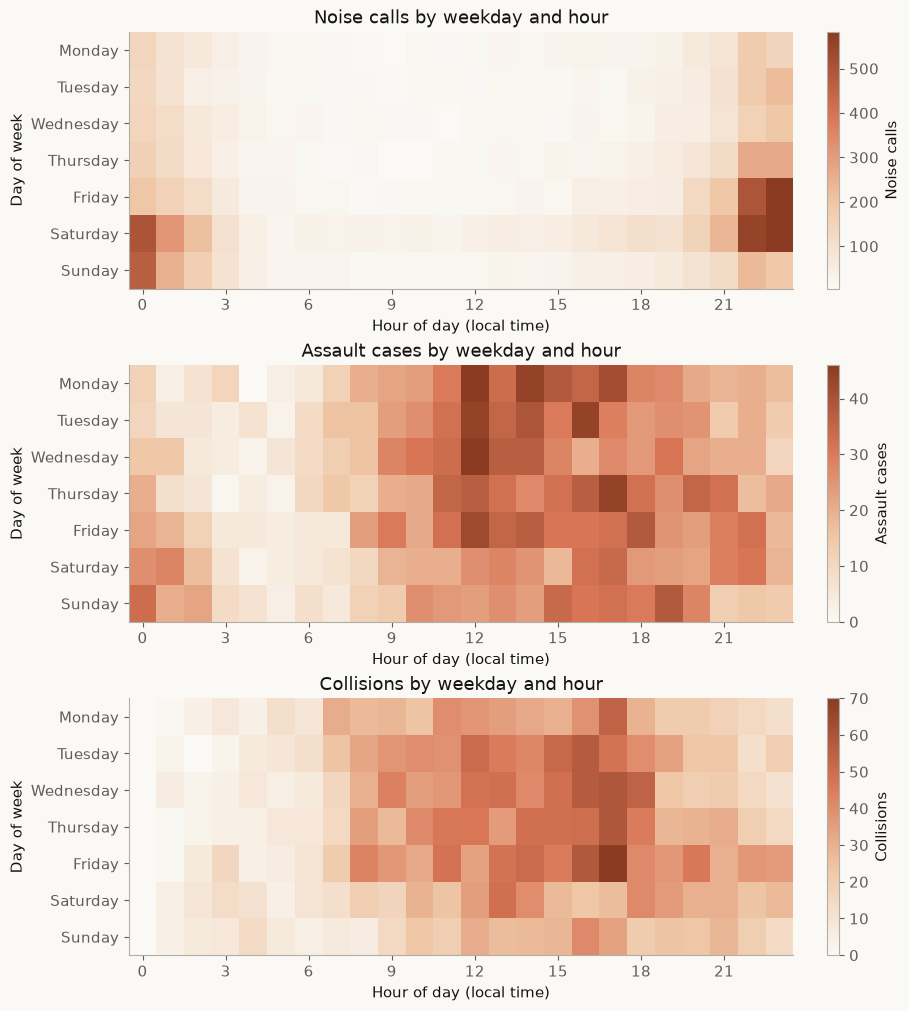

In [3]:
# Drop events without a time; each table is 7 weekdays by 24 hours
a2_events = {
    "Noise calls": timed_hours(noise_calls),
    "Assault cases": timed_hours(assaults),
    "Collisions": timed_hours(collisions),
}
a2_tables = {name: hour_weekday_table(events) for name, events in a2_events.items()}

fig, axes = plt.subplots(3, 1, figsize=(9, 10), constrained_layout=True)
for ax, (name, table) in zip(axes, a2_tables.items()):
    plot_hour_weekday_heatmap(
        table, f"{name} by weekday and hour", ax=ax, count_label=name
    )
fig.savefig(figures / "03_a2_heatmaps.png")

# Save the counts in long form: one row per event type, weekday, and hour
a2_counts = (
    pd.concat({name: table.stack() for name, table in a2_tables.items()})
    .rename("count")
    .rename_axis(["events", "weekday", "hour"])
    .reset_index()
)
a2_counts.to_csv(results / "03_a2_hour_weekday_counts.csv", index=False)

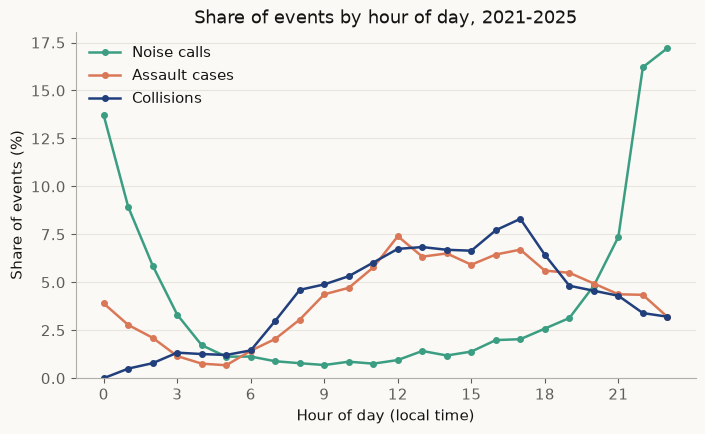

In [4]:
# Share of each event type in each hour, so the three lines compare fairly
a2_profiles = pd.DataFrame(
    {name: hourly_profile(events)["all"] for name, events in a2_events.items()}
)
fig, ax = plt.subplots()
plot_hourly_profiles(a2_profiles, "Share of events by hour of day, 2021-2025", ax=ax)
fig.savefig(figures / "03_a2_hourly_profiles.png")

### Peaks, with checks

41 assault cases sit at exactly 00:00:00 and 65 at exactly 12:00:00, which look like stand-ins for an unknown time. Collision times before 06:00 look unreliable (see `data/README.md`).

In [5]:
# Checks: assaults without the placeholder times 00:00:00 and
# 12:00:00 (crime cases pile up at both), and collisions from 06:00 on only
clock_times = assaults["local_time"].dt.strftime("%H:%M:%S")
midnight = clock_times.eq("00:00:00")
placeholder = clock_times.isin(["00:00:00", "12:00:00"])
a2_checks = {
    "Assault cases without 00:00:00": timed_hours(assaults.loc[~midnight]),
    "Assault cases without 00:00:00 or 12:00:00": timed_hours(
        assaults.loc[~placeholder]
    ),
    "Collisions 06:00-23:59": a2_events["Collisions"].query("hour >= 6"),
}

# One row per event type: size, busiest hour and its share, busiest
# weekday, and the busiest weekday and hour cell
peak_rows = []
for name, events in {**a2_events, **a2_checks}.items():
    table = hour_weekday_table(events)
    profile = hourly_profile(events)["all"]
    weekday, hour = table.stack().idxmax()
    peak_rows.append(
        {
            "events": name,
            "n": int(table.to_numpy().sum()),
            "peak_hour": int(profile.idxmax()),
            "peak_hour_share": round(float(profile.max()), 3),
            "busiest_weekday": table.sum(axis=1).idxmax(),
            "busiest_cell": f"{weekday} {hour:02d}:00",
        }
    )
a2_peaks = pd.DataFrame(peak_rows)
a2_peaks.to_csv(results / "03_a2_peaks.csv", index=False)
a2_peaks

,events,n,peak_hour,peak_hour_share,busiest_weekday,busiest_cell
0,Noise calls,12693,23,0.172,Saturday,Friday 23:00
1,Assault cases,3567,12,0.074,Friday,Monday 12:00
2,Collisions,4213,17,0.083,Friday,Friday 17:00
3,Assault cases without 00:00:00,3526,12,0.075,Friday,Monday 12:00
4,Assault cases without 00:00:00 or 12:00:00,3461,17,0.069,Friday,Monday 14:00
5,Collisions 06:00-23:59,3999,17,0.088,Friday,Friday 17:00


In [6]:
# Save the hour profile of each event type and each check: one row per
# hour, one column per group, each cell the share of that group's events
a2_all_profiles = pd.DataFrame(
    {
        name: hourly_profile(events)["all"]
        for name, events in {**a2_events, **a2_checks}.items()
    }
)
a2_all_profiles.round(6).to_csv(results / "03_a2_hourly_profiles.csv")

## A6 · Calls vs. stops by hour

Officer-initiated traffic and pedestrian stops are taken out of the call side, so we compare resident calls with stops.

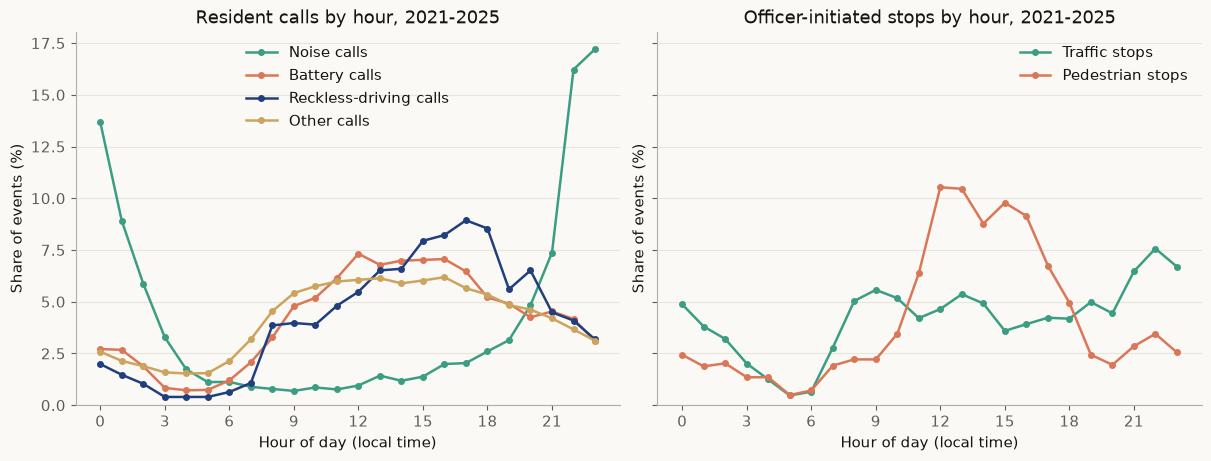

In [7]:
# Stops logged in CFS: officer-initiated rows of the two stop types
officer = calls["Source"].eq("Officer Initiated")
stop_types = {
    "Traffic stops": "CFS T - Traffic Stop",
    "Pedestrian stops": "CFS 1194 - Pedestrian Stop",
}
a6_stops = {
    name: timed_hours(calls.loc[officer & calls["Call Type"].eq(call_type)])
    for name, call_type in stop_types.items()
}

# Calls: everything that is not officer-initiated, by call group
resident = calls.loc[~officer]
a6_calls = {
    "Noise calls": timed_hours(resident.loc[resident["call_group"].eq("noise")]),
    "Battery calls": timed_hours(resident.loc[resident["call_group"].eq("battery")]),
    "Reckless-driving calls": timed_hours(
        resident.loc[resident["call_group"].eq("reckless")]
    ),
    "Other calls": timed_hours(resident.loc[resident["call_group"].eq("other")]),
}
a6_profiles = {
    name: hourly_profile(events)["all"]
    for name, events in {**a6_calls, **a6_stops}.items()
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, constrained_layout=True)
plot_hourly_profiles(
    pd.DataFrame({name: a6_profiles[name] for name in a6_calls}),
    "Resident calls by hour, 2021-2025",
    ax=axes[0],
)
plot_hourly_profiles(
    pd.DataFrame({name: a6_profiles[name] for name in a6_stops}),
    "Officer-initiated stops by hour, 2021-2025",
    ax=axes[1],
)
fig.savefig(figures / "03_a6_hourly_profiles.png")

In [8]:
# Save the hour profiles behind the figure: one row per hour, one column
# per call group and stop type
pd.DataFrame(a6_profiles).round(6).to_csv(results / "03_a6_hourly_profiles.csv")

### How much do the hour profiles overlap?

Overlap = sum over hours of the smaller share (1 = same profile). The permutation test shuffles group labels with the project seed.

In [9]:
# Every call group against every stop type. "Other calls" has over
# 200,000 rows, so it gets the overlap only; a test on it would be slow
# and would flag any small gap anyway
overlap_rows = []
for call_name, call_events in a6_calls.items():
    for stop_name, stop_events in a6_stops.items():
        row = {
            "first": call_name,
            "second": stop_name,
            "n_first": len(call_events),
            "n_second": len(stop_events),
            "overlap": profile_overlap(a6_profiles[call_name], a6_profiles[stop_name]),
            "p_value": float("nan"),
        }
        if call_name != "Other calls":
            test = overlap_permutation_test(call_events["hour"], stop_events["hour"])
            row["p_value"] = test["p_value"]
        overlap_rows.append(row)

# Check: CFS traffic stops against Stop Data vehicle stops, 2024-2025
cfs_traffic = in_window(a6_stops["Traffic stops"], STOP_YEARS_START, STOP_YEARS_END)
stop_data = timed_hours(in_window(stops, STOP_YEARS_START, STOP_YEARS_END))
overlap_rows.append(
    {
        "first": "CFS traffic stops 2024-2025",
        "second": "Stop Data vehicle stops 2024-2025",
        "n_first": len(cfs_traffic),
        "n_second": len(stop_data),
        "overlap": profile_overlap(
            hourly_profile(cfs_traffic)["all"], hourly_profile(stop_data)["all"]
        ),
        "p_value": float("nan"),
    }
)
a6_overlap = pd.DataFrame(overlap_rows).round({"overlap": 3})
a6_overlap.to_csv(results / "03_a6_overlap.csv", index=False)
a6_overlap

,first,second,n_first,n_second,overlap,p_value
0,Noise calls,Traffic stops,12631,19024,0.601,0.0001
1,Noise calls,Pedestrian stops,12631,2668,0.390,0.0001
2,Battery calls,Traffic stops,5013,19024,0.812,0.0001
3,Battery calls,Pedestrian stops,5013,2668,0.847,0.0001
4,Reckless-driving calls,Traffic stops,2518,19024,0.753,0.0001
5,Reckless-driving calls,Pedestrian stops,2518,2668,0.797,0.0001
6,Other calls,Traffic stops,211469,19024,0.838,NaN
7,Other calls,Pedestrian stops,211469,2668,0.800,NaN
8,CFS traffic stops 2024-2025,Stop Data vehicle stops 2024-2025,8480,6310,0.937,NaN


## A7 · Traffic stops vs. collisions, weekdays and weekends

Stop Data vehicle stops and collisions, 2024-2025.

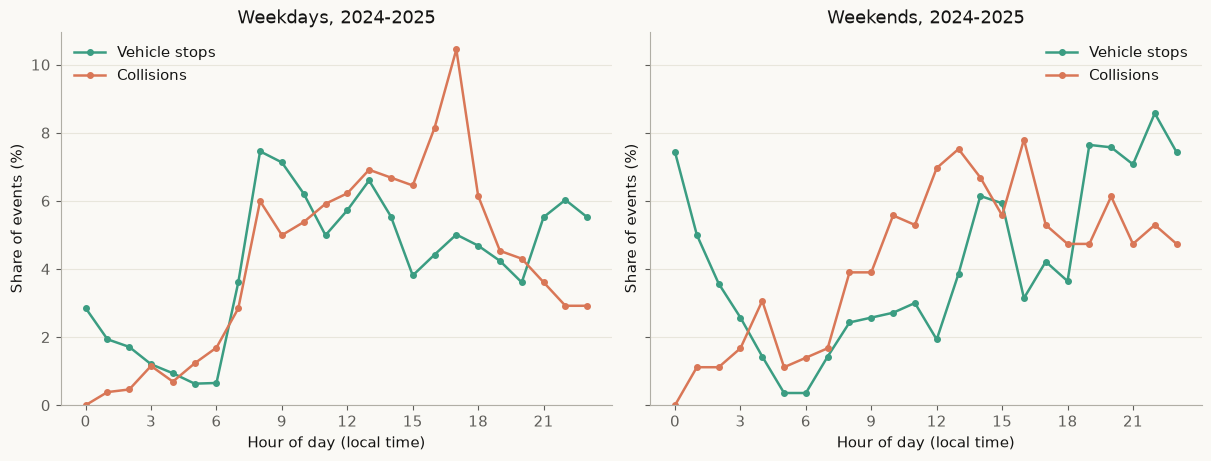

In [10]:
# Same two years for both sources; reuse the timed stops from above
a7_collisions = timed_hours(
    in_window(load_collisions(), STOP_YEARS_START, STOP_YEARS_END)
)
a7_stops = stop_data

# Split each source into weekdays and weekends: one table of hour
# profiles per kind of day
a7_profiles = {
    label: pd.DataFrame(
        {
            "Vehicle stops": hourly_profile(
                a7_stops.loc[a7_stops["is_weekend"].eq(weekend)]
            )["all"],
            "Collisions": hourly_profile(
                a7_collisions.loc[a7_collisions["is_weekend"].eq(weekend)]
            )["all"],
        }
    )
    for label, weekend in [("Weekdays", False), ("Weekends", True)]
}

# Draw weekdays and weekends side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, constrained_layout=True)
for ax, (label, profiles) in zip(axes, a7_profiles.items()):
    plot_hourly_profiles(profiles, f"{label}, 2024-2025", ax=ax)
fig.savefig(figures / "03_a7_stops_collisions.png")

# Save the four profiles: one row per hour, one column per kind of day
# and source, for example "Weekends, Vehicle stops"
a7_saved = pd.concat(a7_profiles, axis=1)
a7_saved.columns = [f"{label}, {source}" for label, source in a7_saved.columns]
a7_saved.round(6).to_csv(results / "03_a7_hourly_profiles.csv")

In [11]:
# Overlap and permutation test for all days, weekdays, and weekends,
# each with all 24 hours and with 06:00-23:59 only (unreliable early
# collision times)
day_sets = {
    "All days": lambda events: events,
    "Weekdays": lambda events: events.loc[~events["is_weekend"]],
    "Weekends": lambda events: events.loc[events["is_weekend"]],
}
a7_rows = []
for days, pick in day_sets.items():
    for hours, first_hour in [("00:00-23:59", 0), ("06:00-23:59", 6)]:
        stop_hours = pick(a7_stops).query("hour >= @first_hour")["hour"]
        collision_hours = pick(a7_collisions).query("hour >= @first_hour")["hour"]
        test = overlap_permutation_test(stop_hours, collision_hours)
        a7_rows.append(
            {
                "days": days,
                "hours": hours,
                "n_stops": len(stop_hours),
                "n_collisions": len(collision_hours),
                "overlap": round(test["overlap"], 3),
                "p_value": test["p_value"],
            }
        )
a7_overlap = pd.DataFrame(a7_rows)
a7_overlap.to_csv(results / "03_a7_overlap.csv", index=False)
a7_overlap

,days,hours,n_stops,n_collisions,overlap,p_value
0,All days,00:00-23:59,6310,1661,0.814,0.0001
1,All days,06:00-23:59,5570,1581,0.847,0.0001
2,Weekdays,00:00-23:59,4910,1302,0.812,0.0001
3,Weekdays,06:00-23:59,4455,1251,0.840,0.0001
4,Weekends,00:00-23:59,1400,359,0.723,0.0001
5,Weekends,06:00-23:59,1115,330,0.780,0.0001


## Findings

- **Noise is a late-night weekend thing.** 17.2% of noise calls come in the 23:00 hour, and the busiest cell is Friday 23:00. Saturday is the busiest day.
- **Assaults and collisions are daytime events.** Collisions peak at 17:00 (8.3%), and still at 17:00 from 06:00 on. Assault cases seem to peak at 12:00 (7.4%), but 65 of them sit at exactly 12:00:00. Without those and the 41 at 00:00:00, assaults spread evenly over the afternoon: every hour from 13:00 to 17:00 holds 6.1% to 6.9%. Both are busiest on Friday.
- **Traffic stops do not follow noise calls.** Their hour profiles overlap only 0.60. Stops line up better with battery (0.81) and reckless-driving calls (0.75). Pedestrian stops cluster at midday and overlap 0.85 with battery calls but 0.39 with noise calls.
- **Stops and collisions overlap less on weekends.** On weekdays the overlap is 0.81 (0.84 from 06:00). On weekends it drops to 0.72 (0.78): weekend stops pile up from 19:00 to 01:00, while weekend collisions peak in the afternoon.
- CFS traffic stops and Stop Data vehicle stops have almost the same hour profile (overlap 0.94), so both sources tell the same story about when stops happen.

## Limitations

- A call records what someone reported, and an assault time is the time the case says it happened, which can be a guess. Crime cases pile up at exactly 00:00:00 and 12:00:00, so the assault peaks are checked without both.
- Collision times before 06:00 look unreliable in the source, so every collision comparison is repeated for 06:00-23:59.
- Stop Data starts in 2024 and only has vehicle stops, so A7 covers two years.
- Every permutation test gives p = 0.0001, the smallest value 9,999 shuffles allow. With this many events any gap is "significant", and the test treats events as independent, so we read the overlap, not the p-value.
- All of this is description. It does not say that stops change collisions or that calls cause stops.